In [5]:

import matplotlib.gridspec as gridspec
import os
import sys

import scipy.stats
import umap
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder
from BWM.models.isometric_autoencoder import get_density_proxy
active_lambda = 0.1 # Default value if not imported
sys.path.append(os.path.abspath('../../'))
from BWM.ScriptsandFunctions.bwm_functions import *
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [6]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    #row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    #X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_transposed


directory_path='../Data2'
eids = [d for d in os.listdir(directory_path) if os.path.isdir(os.path.join(directory_path, d))]
# result = get_region_response_matrix(
#                 region=['MOs','MOp'],
#                 eids=eids,
#                 directory_path=directory_path,
#                 event="stimOn_times",
#                 conditions=['choice'],
#                 n_pseudo=25,
#                 threshold=5,
#                 std_above=50,
#                 std_below=50,
#                 filter_significant=False,
#                 n_steps=100,
#                 step=0.01,
#                 sigma=1,
#                 mapping='Beryl'
#             )
# pseudo_response_tensor =result[0]
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
# #pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]
#
# selected_eid = '6274dda8-3a59-4aa1-95f8-a8a549c46a26' # Example EID
# directory_path = '../Data2'
# event = 'stimOn_times'
# conditions = ['choice']
#
# result = get_eid_response_matrix(
#     selected_eid, directory_path, event, conditions,
#     n_pseudo=25,
#     threshold = 0,
#
#     filter_significant=False,
#     n_steps=100, step=0.01 , sigma=2,
# )
#
#
# pseudo_response_tensor, common_conditions, beryl_regions, cosmos_regions, cluster_ids = result


In [8]:
eid = 'b69b86be-af7d-4ecf-8cbf-0cd356afa1bd'
directory_path = '../Data2'
output_dir = '../Figures/DensMAP_Projections'
os.makedirs(output_dir, exist_ok=True)

event = 'stimOn_times'
conditions = ['choice']
full_path = os.path.join(directory_path, eid)

clusters = pd.read_pickle(os.path.join(full_path, 'clusters.pkl'))
# Mapping depends on what's used in bwm_functions, usually 'Beryl' or 'Cosmos'
# br.id2acronym is used in bwm_functions.py to get region acronyms.
# We just need to check if 'CP' is among the regions for these neurons.
# In bwm_functions, it uses mapping='Beryl' by default for some functions.

# Load all neurons from the EID
res = get_eid_response_matrix(
eid, directory_path, event, conditions,
n_pseudo=25, threshold=None, std_above=50, std_below=50, start_time=0,
filter_significant=False, n_steps=100, step=0.005, stride=0.005, sigma=2
)


pseudo_response_tensor, _, beryl_regs, cosmos_regs, _ = res

In [9]:
def trial_variability(x):

    z = (x-np.mean(x,axis=(0,1,2)))/np.std(x,axis=(0,1,2))
    return (
        np.mean(np.std(z, axis=0),axis=(0,1)))

variability = trial_variability(pseudo_response_tensor)
pseudo_response_tensor=pseudo_response_tensor[:,:,:,variability<1]

def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    speed= np.mean(np.abs(np.diff(z,axis=1)),axis=(0,1))
    return speed

msd_data = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))

X_input = iso_ae_preprocessing(pseudo_response_tensor)


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_57685/1206202115.py:3: RuntimeWarning: invalid value encountered in divide
  z = (x-np.mean(x,axis=(0,1,2)))/np.std(x,axis=(0,1,2))


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.base import BaseEstimator, TransformerMixin
from tqdm.auto import tqdm

class MLP(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim, depth):
        super(MLP, self).__init__()
        layers = []
        curr_dim = input_dim
        for _ in range(depth):
            layers.append(nn.Linear(curr_dim, hidden_dim))
            layers.append(nn.ReLU())
            curr_dim = hidden_dim
        layers.append(nn.Linear(curr_dim, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

class ParametricDensMAP(BaseEstimator, TransformerMixin):
    def __init__(self, latent_dim=2, hidden_dim=64, depth=2, k=15, k_farthest=10, 
                 epochs=100, batch_size=32, lr=1e-3, device='cpu', verbose=True, repulsion_weight=1.0):
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.depth = depth
        self.k = k
        self.k_farthest = k_farthest
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.device = device
        self.verbose = verbose
        self.repulsion_weight = repulsion_weight
        self.model_ = None

    def fit(self, X, y=None):
        if isinstance(X, np.ndarray):
            X = torch.FloatTensor(X)
        
        input_dim = X.shape[1]
        self.model_ = MLP(input_dim, self.latent_dim, self.hidden_dim, self.depth).to(self.device)
        
        dataset = TensorDataset(X)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)
        
        optimizer = optim.Adam(self.model_.parameters(), lr=self.lr)
        
        pbar = tqdm(range(self.epochs), desc="Training ParametricDensMAP", disable=not self.verbose, file=sys.stdout)
        
        for epoch in pbar:
            self.model_.train()
            epoch_loss = 0
            epoch_dist_loss = 0
            for batch_x, in dataloader:
                batch_x = batch_x.to(self.device)
                optimizer.zero_grad()
                
                z = self.model_(batch_x)
                
                # Compute loss: preserve k-NN distances
                dist_loss = self._compute_losses(batch_x, z)
                
                loss = dist_loss
                
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
                epoch_dist_loss += dist_loss.item()
            
            pbar.set_postfix({
                'loss': epoch_loss / len(dataloader),
                'dist': epoch_dist_loss / len(dataloader)
            })
            
        return self

    def _compute_losses(self, x, z):
        k = min(self.k, x.shape[0] - 1)
        k_far = min(self.k_farthest, x.shape[0] - 1)
        
        if k < 1:
            return torch.tensor(0.0, device=x.device, requires_grad=True)
            
        # Distances in input space
        dist_x = torch.cdist(x, x)
        # Distances in latent space
        dist_z = torch.cdist(z, z)
        
        # 1. k-Nearest Neighbors Loss
        _, knn_indices = torch.topk(dist_x, k + 1, largest=False)
        knn_indices = knn_indices[:, 1:] # exclude self
        
        batch_indices = torch.arange(x.shape[0], device=x.device).view(-1, 1).expand(-1, k)
        
        knn_dist_x = dist_x[batch_indices, knn_indices]
        knn_dist_z = dist_z[batch_indices, knn_indices]
        
        log_knn_dist_x = torch.log(knn_dist_x + 1e-8)
        log_knn_dist_z = torch.log(knn_dist_z + 1e-8)
        
        x_flat = log_knn_dist_x.reshape(-1)
        z_flat = log_knn_dist_z.reshape(-1)
        
        vx = x_flat - torch.mean(x_flat)
        vy = z_flat - torch.mean(z_flat)
        sx = torch.sqrt(torch.sum(vx ** 2))
        sy = torch.sqrt(torch.sum(vy ** 2))
        
        if sx > 1e-8 and sy > 1e-8:
            corr = torch.sum(vx * vy) / (sx * sy)
            knn_loss = 1 - corr
        else:
            knn_loss = torch.tensor(0.0, device=x.device, requires_grad=True)
            
        # 2. k-Farthest Neighbors Loss (Repulsion Force)
        if k_far > 0:
            _, far_indices = torch.topk(dist_x, k_far, largest=True)
            
            batch_indices_far = torch.arange(x.shape[0], device=x.device).view(-1, 1).expand(-1, k_far)
            
            far_dist_x = dist_x[batch_indices_far, far_indices]
            far_dist_z = dist_z[batch_indices_far, far_indices]
            
            log_far_dist_x = torch.log(far_dist_x + 1e-8)
            log_far_dist_z = torch.log(far_dist_z + 1e-8)
            
            x_far_flat = log_far_dist_x.reshape(-1)
            z_far_flat = log_far_dist_z.reshape(-1)
            
            vx_far = x_far_flat - torch.mean(x_far_flat)
            vy_far = z_far_flat - torch.mean(z_far_flat)
            sx_far = torch.sqrt(torch.sum(vx_far ** 2))
            sy_far = torch.sqrt(torch.sum(vy_far ** 2))
            
            if sx_far > 1e-8 and sy_far > 1e-8:
                corr_far = torch.sum(vx_far * vy_far) / (sx_far * sy_far)
                far_loss = 1 - corr_far
            else:
                far_loss = torch.tensor(0.0, device=x.device, requires_grad=True)
        else:
            far_loss = torch.tensor(0.0, device=x.device, requires_grad=True)
            
        return knn_loss + self.repulsion_weight * far_loss

    def transform(self, X):
        if isinstance(X, np.ndarray):
            X = torch.FloatTensor(X)
        self.model_.eval()
        with torch.no_grad():
            z = self.model_(X.to(self.device))
        return z.cpu().numpy()

# Initialize and train the model
model = ParametricDensMAP(
    latent_dim=2, 
    hidden_dim=64,
    depth=3,
    k=500,
    k_farthest=1,
    repulsion_weight=0.001,
    epochs=5000,
    batch_size=32, 
    lr=1e-3, 
    device=device
)

model.fit(X_input)
z = model.transform(X_input)

# Plot the resulting embedding



Training ParametricDensMAP:   0%|          | 0/5000 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [11]:

z = model.transform(X_input)

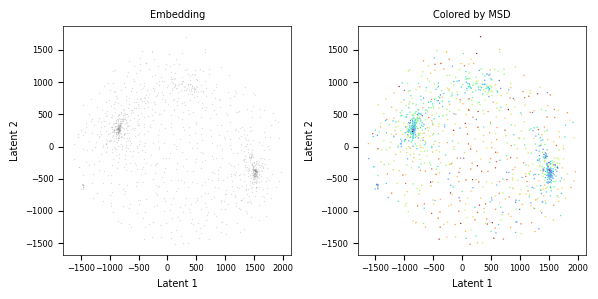

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3))

sns.scatterplot(x=z[:, 0], y=z[:, 1], color='gray', s=1, alpha=0.25, ax=ax1)
ax1.set_title('Embedding')
ax1.set_xlabel('Latent 1')
ax1.set_ylabel('Latent 2')

sns.scatterplot(x=z[:, 0], y=z[:, 1], hue=msd_data, palette='turbo', s=1, alpha=1, ax=ax2)
ax2.set_title('Colored by MSD')
ax2.set_xlabel('Latent 1')
ax2.set_ylabel('Latent 2')
ax2.get_legend().remove()

plt.tight_layout()
plt.show()

Fitting densmap
Condition 0, Time 0
Condition 0, Time 10
Condition 0, Time 20
Condition 0, Time 40
Condition 0, Time 60
Condition 0, Time 70
Condition 1, Time 0
Condition 1, Time 10
Condition 1, Time 20
Condition 1, Time 40
Condition 1, Time 60
Condition 1, Time 70


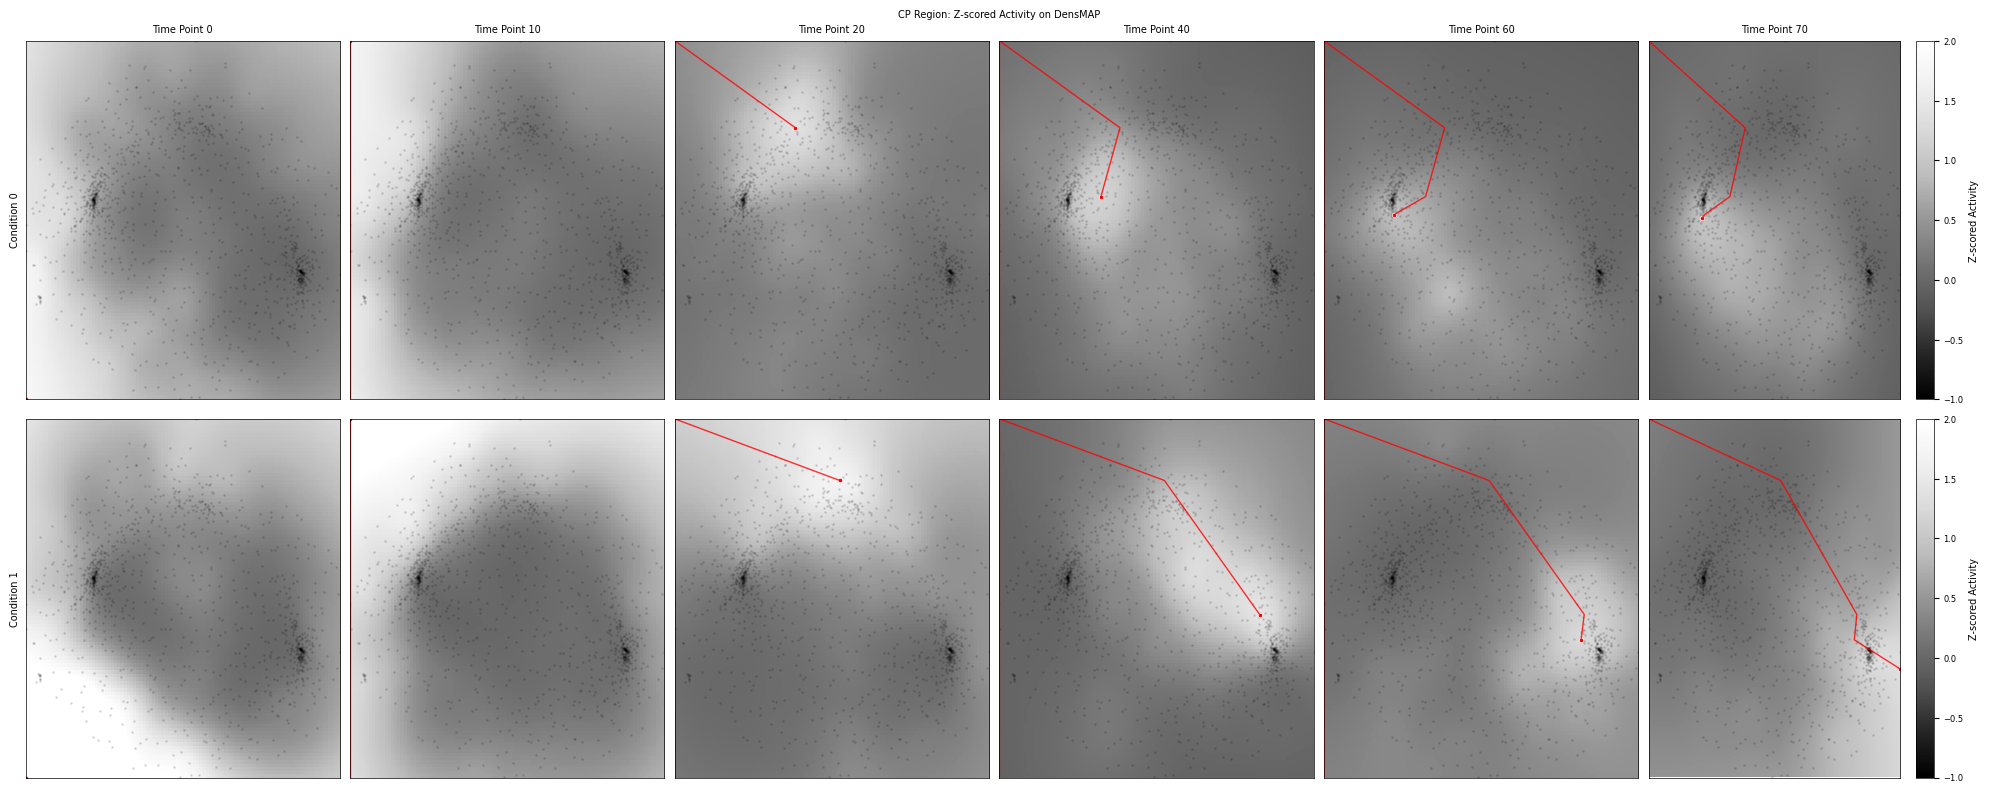

In [13]:
# 7. CP Data Activity Visualization
# pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
#pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]

# Preprocessing CP data
# variability = trial_variability(pseudo_response_tensor)
# pseudo_response_tensor = pseudo_response_tensor[:,:,:,variability<.7]
X_input_cp = X_input

# DensMAP Projection for CP
print('Fitting densmap')
#reducer_cp = umap.UMAP(densmap=True, dens_lambda=2,n_neighbors=50)
embedding_cp = z

# Grid Setup for CP
avg_response_cp = np.mean(pseudo_response_tensor, axis=0)
nx, ny = 100, 100
x_grid_cp = np.linspace(embedding_cp[:, 0].min() - 0.5, embedding_cp[:, 0].max() + 0.5, nx)
y_grid_cp = np.linspace(embedding_cp[:, 1].min() - 0.5, embedding_cp[:, 1].max() + 0.5, ny)
xx_cp, yy_cp = np.meshgrid(x_grid_cp, y_grid_cp)

# Select condition and time points
time_points = [0,10,20,40,60,70]
n_time_points = len(time_points)
n_conditions = 2

fig, axes = plt.subplots(n_conditions, n_time_points, figsize=(20, 8))

# Z-score the activity using data from both conditions
activity_mean = np.mean(avg_response_cp, axis=(0, 1), keepdims=True)
activity_std = np.std(avg_response_cp, axis=(0, 1), keepdims=True)

for cond_idx in range(n_conditions):
    activity_zscored = (avg_response_cp[cond_idx] - activity_mean[0]) / (activity_std[0] + 1e-8)
    activity_zscored = torch.nn.functional.leaky_relu(torch.FloatTensor(activity_zscored)).numpy()

    peak_locations = []
    for i, t in enumerate(time_points):
        print(f"Condition {cond_idx}, Time {t}")
        ax = axes[cond_idx, i]
        z_t = activity_zscored[t, :]
        rbf_t = Rbf(embedding_cp[:, 0], embedding_cp[:, 1], z_t, function='multiquadric', smooth=50)
        z_grid_t = rbf_t(xx_cp, yy_cp)

        # Find peak location in the grid
        max_idx = np.unravel_index(np.argmax(z_grid_t), z_grid_t.shape)
        peak_locations.append((xx_cp[max_idx], yy_cp[max_idx]))
        current_peaks = np.array(peak_locations)

        im = ax.imshow(z_grid_t, extent=(x_grid_cp.min(), x_grid_cp.max(), y_grid_cp.min(), y_grid_cp.max()),
                           origin='lower', cmap='Greys_r', aspect='auto', vmin=-1, vmax=2)
        ax.scatter(embedding_cp[:, 0], embedding_cp[:, 1], c='black', s=1, alpha=0.1)

        # Plot the trace of peak locations for the selected time points
        ax.plot(current_peaks[:, 0], current_peaks[:, 1], color='red', linewidth=1, alpha=0.8)
        ax.scatter(current_peaks[-1, 0], current_peaks[-1, 1], color='red', s=10, edgecolors='white', linewidth=0.5)

        if cond_idx == 0:
            ax.set_title(f'Time Point {t}')
        if i == 0:
            ax.set_ylabel(f'Condition {cond_idx}')
        ax.set_xticks([])
        ax.set_yticks([])
        if i == n_time_points - 1:
            plt.colorbar(im, ax=ax, label='Z-scored Activity')

plt.suptitle(f'CP Region: Z-scored Activity on DensMAP')
plt.tight_layout()
plt.savefig('../Figures/CP_Activity_Visualization.png', dpi=300, bbox_inches='tight')
plt.show()
